# Experiment 8 — Hindi Abstractive Text Summarization using mT5 and mBART

This notebook fine-tunes **mT5** and **mBART** on the Hindi configuration of the XL-Sum dataset, generates summaries, and compares **ROUGE-1, ROUGE-2, ROUGE-L, and multilingual BERTScore (mBERTScore)**.

The notebook uses configurable subsets so it can run on a GPU. Increase `TRAIN_LIMIT`, `VAL_LIMIT`, and `TEST_LIMIT` for more extensive experiments if your GPU time and memory allow it.

## 1. Install required libraries

In [1]:
!pip -q install -U transformers datasets accelerate sentencepiece sacrebleu rouge-score bert-score pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires 

## 2. Imports and experiment configuration

In [2]:
import os
import gc
import json
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    set_seed
)
from rouge_score import rouge_scorer
from bert_score import score as bert_score

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# XL-Sum language configuration
LANGUAGE = "hindi"

# Subset sizes: adjust upward for a larger experiment
TRAIN_LIMIT = 2000
VAL_LIMIT = 300
TEST_LIMIT = 300

MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 128
NUM_EPOCHS = 1

# Model checkpoints
MT5_CHECKPOINT = "google/mt5-small"
MBART_CHECKPOINT = "facebook/mbart-large-50-many-to-many-mmt"

OUTPUT_DIR = "/kaggle/working/experiment8_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda
GPU: Tesla T4
Output directory: /kaggle/working/experiment8_results


## 3. Load the Hindi XL-Sum dataset

In [3]:

from datasets import load_dataset

# Load XL-Sum Hindi directly from its Parquet files
# This works with newer Hugging Face datasets versions.

BASE_URL = "https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/651dcf16e996d411b12f0bb7b8fc671788f24193/hindi/"

data_files = {
    "train": [
        BASE_URL + "xlsum-train-00000-of-00002.parquet",
        BASE_URL + "xlsum-train-00001-of-00002.parquet"
    ],
    "validation": "https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/014d1559dcde03c72beff7d2e617f9792a54fd39/hindi/xlsum-validation.parquet",
    "test": BASE_URL + "xlsum-test.parquet"
}

dataset = load_dataset(
    "parquet",
    data_files=data_files
)

print(dataset)

print("Available splits:", list(dataset.keys()))
print("Columns:", dataset["train"].column_names)

print("\nExample article:\n")
print(dataset["train"][0]["text"][:700])

print("\nReference summary:\n")
print(dataset["train"][0]["summary"])

hindi/xlsum-train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

hindi/xlsum-train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

hindi/xlsum-train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

hindi/xlsum-train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

hindi/xlsum-validation.parquet: reconstructing file:   0%|          |  0.00B / 21.4MB            

hindi/xlsum-validation.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 70778
    })
    validation: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8847
    })
    test: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8847
    })
})
Available splits: ['train', 'validation', 'test']
Columns: ['id', 'url', 'title', 'summary', 'text']

Example article:

नेपाल में इस दौरे की भरपूर तैयारियां चल रही हैं. इसकी ख़ास वजह भी है क्योंकि 23 साल बाद कोई चीनी राष्ट्रपति नेपाल पहुंच रहा है. नेपाल के प्रधानमंत्री केपी शर्मा ओली के विदेश मामलों के सलाहकार डॉ. राजन भट्टाराई ने इस दौरे को ऐतिहासिक बताया है. उन्होंने बताया कि चीन के राष्ट्रपति के साथ उनका एक प्रतिनिधि दल भी होगा. दोनों देशों के बीच कई समझौते होने की बात भी कही जा रही है. चीन के राष्ट्रपति और नेपाल के प्रधानमंत्री के बीच आधिकारिक बैठक भी तय हुई है. समाप्त नेपाल जाने से पहले चीन के राष्ट्रपति भारत में प्रधानमंत्री नरे

## 4. Prepare train, validation, and test subsets

In [4]:
# The XL-Sum dataset uses 'text' for the article and 'summary' for its reference summary.
# Keep only the columns needed by this experiment.
def clean_split(split, limit):
    split = split.select(range(min(limit, len(split))))
    split = split.filter(
        lambda x: x["text"] is not None
        and x["summary"] is not None
        and len(x["text"].strip()) > 0
        and len(x["summary"].strip()) > 0
    )
    return split

train_data = clean_split(dataset["train"], TRAIN_LIMIT)
validation_data = clean_split(dataset["validation"], VAL_LIMIT)
test_data = clean_split(dataset["test"], TEST_LIMIT)

print("Training examples:", len(train_data))
print("Validation examples:", len(validation_data))
print("Test examples:", len(test_data))

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Training examples: 2000
Validation examples: 300
Test examples: 300


## 5. Shared preprocessing and training function

In [7]:
def prepare_model_data(tokenizer, model_name):
    # mT5 expects a task prefix. mBART does not.
    def preprocess(batch):
        if model_name == "mt5":
            inputs = ["summarize: " + text for text in batch["text"]]
        else:
            inputs = batch["text"]

        model_inputs = tokenizer(
            inputs,
            max_length=MAX_INPUT_LENGTH,
            truncation=True
        )

        labels = tokenizer(
            text_target=batch["summary"],
            max_length=MAX_TARGET_LENGTH,
            truncation=True
        )
        model_inputs["labels"] = labels["input_ids"]
        return model_inputs

    train_tok = train_data.map(
        preprocess, batched=True, remove_columns=train_data.column_names
    )
    val_tok = validation_data.map(
        preprocess, batched=True, remove_columns=validation_data.column_names
    )
    return train_tok, val_tok


def train_one_model(model_name, checkpoint):
    print("\n" + "=" * 70)
    print("Fine-tuning:", model_name, "|", checkpoint)
    print("=" * 70)

    tokenizer = AutoTokenizer.from_pretrained(checkpoint)

    # mBART-50 requires the source and target language codes.
    if model_name == "mbart":
        tokenizer.src_lang = "hi_IN"
        tokenizer.tgt_lang = "hi_IN"

    model = AutoModelForSeq2SeqLM.from_pretrained(checkpoint)

    # Reduce memory usage, especially for mBART on a Colab T4.
    if hasattr(model, "gradient_checkpointing_enable"):
        model.gradient_checkpointing_enable()
    model.config.use_cache = False

    train_tok, val_tok = prepare_model_data(tokenizer, model_name)
    data_collator = DataCollatorForSeq2Seq(
        tokenizer=tokenizer,
        model=model,
        label_pad_token_id=-100
    )

    model_output_dir = os.path.join(OUTPUT_DIR, model_name)

    # mBART-large is memory intensive; use a smaller per-device batch.
    per_device_batch = 1 if model_name == "mbart" else 4
    grad_accumulation = 8 if model_name == "mbart" else 2

    training_args = Seq2SeqTrainingArguments(
        output_dir=model_output_dir,
        num_train_epochs=NUM_EPOCHS,
        learning_rate=5e-5,
        per_device_train_batch_size=per_device_batch,
        per_device_eval_batch_size=1 if model_name == "mbart" else 4,
        gradient_accumulation_steps=grad_accumulation,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        save_total_limit=1,
        predict_with_generate=False,
        fp16=torch.cuda.is_available(),
        gradient_checkpointing=True,
        report_to="none",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False
    )

    trainer = Seq2SeqTrainer(
        model=model,
        args=training_args,
        train_dataset=train_tok,
        eval_dataset=val_tok,
        data_collator=data_collator
    )

    trainer.train()
    trainer.save_model(model_output_dir)
    tokenizer.save_pretrained(model_output_dir)

    # Re-enable cache for faster generation after training.
    model.config.use_cache = True

    print("Saved fine-tuned model to:", model_output_dir)
    return model, tokenizer, model_output_dir

## 6. Fine-tune mT5

In [8]:
mt5_model, mt5_tokenizer, mt5_path = train_one_model(
    "mt5", MT5_CHECKPOINT
)


Fine-tuning: mt5 | google/mt5-small


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: Us

Epoch,Training Loss,Validation Loss
1,32.784370,7.528589


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned model to: /kaggle/working/experiment8_results/mt5


## 7. Release memory before loading/training mBART

In [9]:
# Keep the fine-tuned mT5 checkpoint on disk; release its GPU memory.
del mt5_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("GPU memory cleared where possible.")

GPU memory cleared where possible.


## 8. Fine-tune mBART

In [10]:
mbart_model, mbart_tokenizer, mbart_path = train_one_model(
    "mbart", MBART_CHECKPOINT
)


Fine-tuning: mbart | facebook/mbart-large-50-many-to-many-mmt


config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned model to: /kaggle/working/experiment8_results/mbart


## 9. Generate summaries

In [11]:
def generate_summaries(model_path, model_name, data, batch_size=2):
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    if model_name == "mbart":
        tokenizer.src_lang = "hi_IN"
        tokenizer.tgt_lang = "hi_IN"

    model = AutoModelForSeq2SeqLM.from_pretrained(model_path).to(DEVICE)
    model.eval()

    articles = list(data["text"])
    references = list(data["summary"])
    predictions = []

    forced_bos_token_id = None
    if model_name == "mbart":
        forced_bos_token_id = tokenizer.convert_tokens_to_ids("hi_IN")

    for start in range(0, len(articles), batch_size):
        batch_articles = articles[start:start + batch_size]
        if model_name == "mt5":
            batch_articles = ["summarize: " + x for x in batch_articles]

        inputs = tokenizer(
            batch_articles,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_LENGTH
        ).to(DEVICE)

        with torch.no_grad():
            generated = model.generate(
                **inputs,
                max_length=MAX_TARGET_LENGTH,
                num_beams=4,
                early_stopping=True,
                no_repeat_ngram_size=3,
                forced_bos_token_id=forced_bos_token_id
            )

        decoded = tokenizer.batch_decode(
            generated, skip_special_tokens=True
        )
        predictions.extend(decoded)

        if (start // batch_size) % 25 == 0:
            print(f"{model_name}: generated {min(start + batch_size, len(articles))}/{len(articles)}")

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return predictions, references


mt5_predictions, references = generate_summaries(
    mt5_path, "mt5", test_data, batch_size=4
)

mbart_predictions, _ = generate_summaries(
    mbart_path, "mbart", test_data, batch_size=1
)

print("Generation completed.")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


mt5: generated 4/300
mt5: generated 104/300
mt5: generated 204/300


Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

mbart: generated 1/300
mbart: generated 26/300
mbart: generated 51/300
mbart: generated 76/300
mbart: generated 101/300
mbart: generated 126/300
mbart: generated 151/300
mbart: generated 176/300
mbart: generated 201/300
mbart: generated 226/300
mbart: generated 251/300
mbart: generated 276/300
Generation completed.


## 10. Evaluate using ROUGE-1, ROUGE-2, and ROUGE-L

In [12]:
def calculate_rouge(predictions, references):
    scorer = rouge_scorer.RougeScorer(
        ["rouge1", "rouge2", "rougeL"],
        use_stemmer=False
    )

    scores = []
    for prediction, reference in zip(predictions, references):
        result = scorer.score(reference, prediction)
        scores.append({
            "ROUGE-1": result["rouge1"].fmeasure,
            "ROUGE-2": result["rouge2"].fmeasure,
            "ROUGE-L": result["rougeL"].fmeasure
        })

    return {
        metric: float(np.mean([item[metric] for item in scores]))
        for metric in ["ROUGE-1", "ROUGE-2", "ROUGE-L"]
    }


mt5_rouge = calculate_rouge(mt5_predictions, references)
mbart_rouge = calculate_rouge(mbart_predictions, references)

print("mT5 ROUGE:", mt5_rouge)
print("mBART ROUGE:", mbart_rouge)

mT5 ROUGE: {'ROUGE-1': 0.004952380952380953, 'ROUGE-2': 0.0, 'ROUGE-L': 0.004952380952380953}
mBART ROUGE: {'ROUGE-1': 0.010555555555555556, 'ROUGE-2': 0.0, 'ROUGE-L': 0.010555555555555556}


## 11. Evaluate using multilingual BERTScore (mBERTScore)

In [13]:
# BERTScore uses contextual multilingual embeddings to compare each generated
# summary with its reference. bert-base-multilingual-cased is the mBERT encoder.
# Run on the generated summaries from the same test subset.

def calculate_mbert_score(predictions, references):
    precision, recall, f1 = bert_score(
        cands=predictions,
        refs=references,
        model_type="bert-base-multilingual-cased",
        num_layers=12,
        batch_size=8,
        device=DEVICE,
        verbose=True,
        rescale_with_baseline=False
    )

    return {
        "mBERT-Precision": float(precision.mean().item()),
        "mBERT-Recall": float(recall.mean().item()),
        "mBERT-F1": float(f1.mean().item())
    }


mt5_bert = calculate_mbert_score(mt5_predictions, references)
mbart_bert = calculate_mbert_score(mbart_predictions, references)

print("mT5 mBERTScore:", mt5_bert)
print("mBART mBERTScore:", mbart_bert)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

... (10 outputs left out)

  0%|          | 0/75 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/38 [00:00<?, ?it/s]

done in 2.46 seconds, 122.11 sentences/sec
mT5 mBERTScore: {'mBERT-Precision': 0.5227389335632324, 'mBERT-Recall': 0.5079909563064575, 'mBERT-F1': 0.5147151947021484}
mBART mBERTScore: {'mBERT-Precision': 0.6249710917472839, 'mBERT-Recall': 0.574618935585022, 'mBERT-F1': 0.5974933505058289}


## 12. Compare both models

In [15]:
results = pd.DataFrame([
    {"Model": "mT5", **mt5_rouge, **mt5_bert},
    {"Model": "mBART", **mbart_rouge, **mbart_bert}
])

display(results.round(4))

# Save numerical results
results.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)
results.to_json(
    os.path.join(OUTPUT_DIR, "model_comparison.json"),
    orient="records",
    indent=2,
    force_ascii=False
)

,Model,ROUGE-1,ROUGE-2,ROUGE-L,mBERT-Precision,mBERT-Recall,mBERT-F1
0,mT5,0.0050,0.0,0.0050,0.5227,0.5080,0.5147
1,mBART,0.0106,0.0,0.0106,0.6250,0.5746,0.5975


## 13. Visualize the comparison

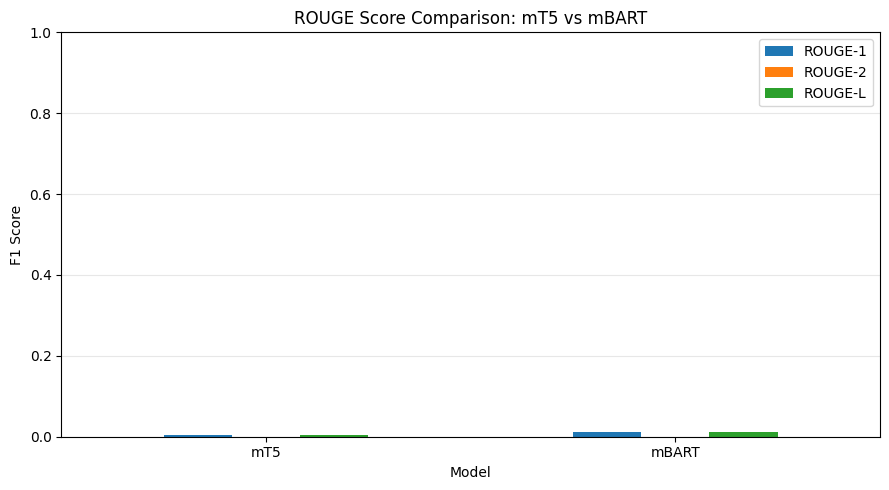

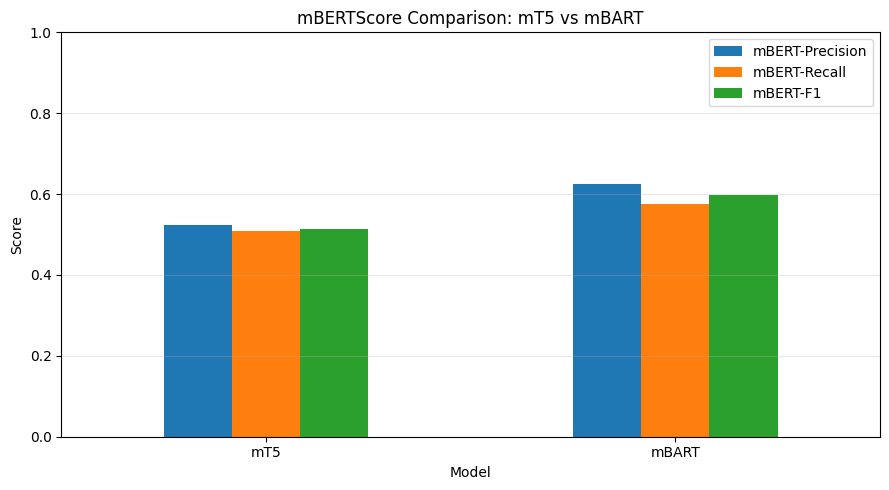

In [16]:
rouge_columns = ["ROUGE-1", "ROUGE-2", "ROUGE-L"]
results.set_index("Model")[rouge_columns].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("ROUGE Score Comparison: mT5 vs mBART")
plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

bert_columns = ["mBERT-Precision", "mBERT-Recall", "mBERT-F1"]
results.set_index("Model")[bert_columns].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("mBERTScore Comparison: mT5 vs mBART")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Inspect sample summaries

In [17]:
sample_count = min(5, len(references))
for i in range(sample_count):
    print("=" * 100)
    print(f"EXAMPLE {i + 1}")
    print("\nARTICLE:\n", test_data[i]["text"][:1000])
    print("\nREFERENCE SUMMARY:\n", references[i])
    print("\nmT5 GENERATED SUMMARY:\n", mt5_predictions[i])
    print("\nmBART GENERATED SUMMARY:\n", mbart_predictions[i])
    print()

EXAMPLE 1

ARTICLE:
 नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. कुछ दिन पहले एटीएस ने मध्य प्रदेश के इंदौर शहर से साध्वी प्रज्ञा सिंह ठाकुर को गिरफ़्तार किया था. नासिक की अदालत ने प्रज्ञा सिंह और दो अन्य अभियुक्तों को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का भी फ़ैसला दिया. आवेदन एटीएस ने अदालत में इस टेस्ट के लिए आवेदन किया था और कहा था कि जाँच के लिए ये टेस्ट ज़रूरी हैं. हालाँकि सरकारी वकील अजय मिश्रा ने यह जानकारी नहीं दी कि साध्वी प्रज्ञा सिंह ठाकुर को कब इस टेस्ट से गुज़रना होगा. पत्रकारों के एक सवाल के जवाब में उन्होंने बताया कि उन्हें इस बात की कोई जानकारी नहीं है कि इसी मामले में दो पूर्व सैनिक अधिकारियों को भी अदालत में पेश किया जाना है. इन दो पूर्व सैनिक अधिकारियों से मालेगाँव और सूरत के मोडासा में हुए धमाकों के सिलसिले में पूछताछ की जा रही है. बीबीसी संवाददाता रेहाना बस्तीवाला ने पुलिस सूत्रों के हवाले से इसकी पुष्टि की है और बताया है कि इनमें एक रिटायर्ड मेजर जनरल भी है.

## 15. Save generated summaries and final results

In [18]:
comparison_output = pd.DataFrame({
    "article": list(test_data["text"]),
    "reference_summary": references,
    "mt5_summary": mt5_predictions,
    "mbart_summary": mbart_predictions
})

summaries_path = os.path.join(OUTPUT_DIR, "generated_summaries.csv")
comparison_output.to_csv(summaries_path, index=False)

print("Saved files:")
for filename in os.listdir(OUTPUT_DIR):
    print("-", os.path.join(OUTPUT_DIR, filename))

Saved files:
- /kaggle/working/experiment8_results/generated_summaries.csv
- /kaggle/working/experiment8_results/mbart
- /kaggle/working/experiment8_results/model_comparison.csv
- /kaggle/working/experiment8_results/mt5
- /kaggle/working/experiment8_results/model_comparison.json


## 16. Download the experiment outputs

Run this cell to download a ZIP containing the evaluation scores, generated summaries, and fine-tuned model folders. Model checkpoints can make the ZIP very large; if you only need the result tables and generated summaries, download those CSV files individually from the Colab file browser.

In [ ]:
import shutil
import os

zip_path = shutil.make_archive(
    "/kaggle/working/experiment8_results",
    "zip",
    OUTPUT_DIR
)

print("ZIP created:", zip_path)

## Notes for your experiment report

- **Dataset:** XL-Sum Hindi configuration.
- **Task:** Abstractive summarization: generate a concise summary of a Hindi article.
- **Models:** `google/mt5-small` and `facebook/mbart-large-50-many-to-many-mmt`, fine-tuned on the same training subset.
- **Automatic evaluation:** ROUGE-1, ROUGE-2, ROUGE-L, and mBERT-based BERTScore (Precision, Recall, F1).
- **Fair comparison:** Both models use the same train/validation/test subsets, input and target length limits, and number of epochs. The batch sizes differ to accommodate model memory requirements.
- **Important:** The notebook does not assume which model performs better. Use the measured scores in the output table to write your conclusion.

If Colab runs out of GPU memory, reduce `TRAIN_LIMIT`, `VAL_LIMIT`, and `TEST_LIMIT`; for mBART, keep batch size at 1. If training is too slow, use fewer training examples or fewer epochs. Record the exact subset sizes and hyperparameters used in your report.